### **Goal**
- Our goal is to build a lightweight, multi-agent system around chat models that customizes the research process.

**__Source Selection__**
-Users can choose any set of input sources for their research.

**__Planning__**

- Users provide a topic, and the system generates a team of AI analysts, each focusing on one sub-topic.
- `Human-in-the-loop` will be used to refine these sub-topics before research begins.

**__LLM Utilization__**

Each analyst will conduct in-depth interviews with an expert AI using the selected sources.
The interview will be a multi-turn conversation to extract detailed insights as shown in the STORM paper.
These interviews will be captured in a using sub-graphs with their internal state.

**__Research Process__**

Experts will gather information to answer analyst questions in parallel.
And all interviews will be conducted simultaneously through map-reduce.

**__Output Format__**

The gathered insights from each interview will be synthesized into a final report.
We'll use customizable prompts for the report, allowing for a flexible output format.

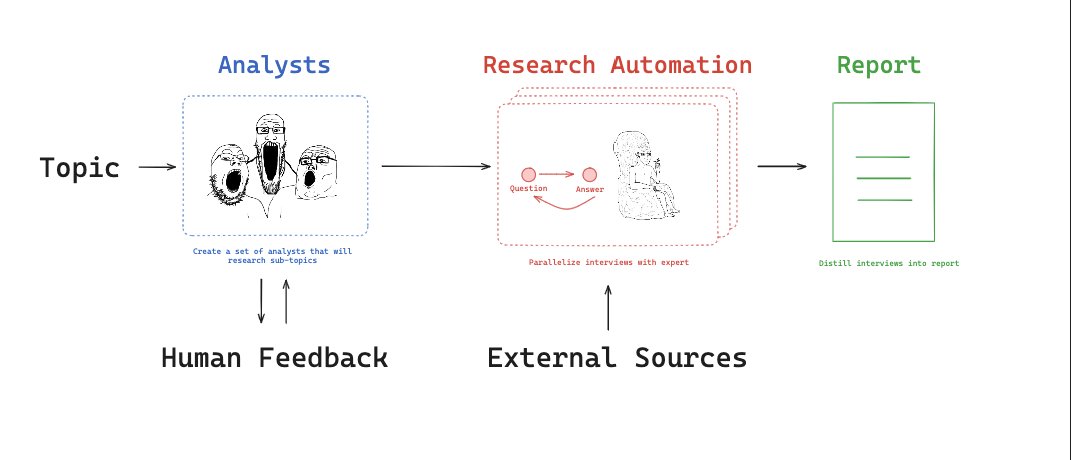

In [ ]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))

from typing import TypedDict

from IPython.display import Image, display
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_core.runnables import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

from utils.utils import Models, Trace, get_invoke_options


In [ ]:
models = Models()
nvidia_model = models.create_nvidia_model()
trace = Trace()
invoke_options = get_invoke_options()

In [ ]:
class Analyst(BaseModel):
    affiliation: str = Field(description="Primary affiliation of the analyst")
    name: str = Field(description="Name of the Analyst")
    role: str = Field(description="Role of the analyst in the context of the topic")
    description: str = Field(
        description="Description of the analyst focus,motives,concerns"
    )

    @property
    def persona(self) -> str:
        return f"Name:{self.name} \nRole:{self.role} \nAffiliation:{self.affiliation} \nDescription:{self.affiliation} \n"


class Perspective(BaseModel):
    analysts: list[Analyst] = Field(
        description="Comprehensive list of analysts with their role and affiliations"
    )


class GeneralAnalystsState(TypedDict):
    topic: str  # Research Topic
    max_analysts: int  # Number of Analysts
    human_analyst_feedback: str  # Human Feedback
    analysts: list[Analyst]  # Analyst asking questions

In [ ]:
analyst_instructions = """ You are tasked to create a set of AI analyst personas. Follow these instructions carefully 
1. First review the research topic:{topic}
2. Examine any editorial feedback that has been optionally provided to guide creating the analysts:{human_analyst_feedback}
3.Determine the most interesting themes based upon the document and /or feedback above 
4. Pick the top {max_analysts} themes
5. Assign one analyst to each theme
"""


def create_analysts(state: GeneralAnalystsState):
    """Create Analysts"""
    topic = state["topic"]
    max_analysts = state["max_analysts"]
    human_analyst_feedback = state.get("human_analyst_feedback", "")
    # INFO Enforce structured output
    structured_llm = nvidia_model.with_structured_output(Perspective)
    sys_msg = analyst_instructions.format(
        topic=topic,
        human_analyst_feedback=human_analyst_feedback,
        max_analysts=max_analysts,
    )

    analysts = structured_llm.invoke(
        [SystemMessage(content=sys_msg)]
        + [HumanMessage(content="Generate the set of analysts")]
    )

    return {"analysts": analysts.analysts}  # pyright:ignore[reportAttributeAccessIssue]

In [ ]:
def human_feedback(state: GeneralAnalystsState):
    """No operations here, this will help to interrupt the graph for user interaction"""
    pass


def should_continue(state: GeneralAnalystsState):
    # INFO Returns the next node to execute
    human_analyst_feedback = state.get("human_analyst_feedback", None)
    if human_analyst_feedback:
        return "create_analysts"
    return END


In [ ]:
builder = StateGraph(GeneralAnalystsState)
builder.add_node("create_analysts", create_analysts)
builder.add_node("human_feedback", human_feedback)
builder.add_edge(START, "create_analysts")
builder.add_edge("create_analysts", "human_feedback")
builder.add_conditional_edges(
    "human_feedback", should_continue, ["create_analysts", END]
)
memory = MemorySaver()
graph = builder.compile(interrupt_before=["human_feedback"], checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))


In [ ]:
config_1: RunnableConfig = {"configurable": {"thread_id": "1"}}

In [ ]:
max_analysts = 5
topic = "The benefits of peptides in women over 40"
for event in graph.stream(
    {"topic": topic, "max_analysts": max_analysts}, config_1, stream_mode="values"
):
    analysts = event.get("analysts", "")
    if analysts:
        for analyst in analysts:
            print(f"Name: {analyst.name}")
            print(f"Affiliation: {analyst.affiliation}")
            print(f"Role: {analyst.role}")
            print(f"Description: {analyst.description}")
            print("-" * 50)


In [ ]:
state = graph.get_state(config_1)
state.next

In [ ]:
graph.update_state(
    config_1,
    {
        "human_analyst_feedback": "Add in someone from a developing country for an inclusive feedback "
    },
    as_node="human_feedback",
)

In [ ]:
for event in graph.stream(None, config_1, stream_mode="values"):
    analysts = event.get("analysts", "")
    if analysts:
        for analyst in analysts:
            print(f"Name: {analyst.name}")
            print(f"Affiliation: {analyst.affiliation}")
            print(f"Role: {analyst.role}")
            print(f"Description: {analyst.description}")
            print("-" * 50)

In [ ]:
final_state = graph.get_state(config_1)
analysts = final_state.values.get("analysts")
final_state.next

In [ ]:
if analysts:
    for analyst in analysts:
        print(f"Name: {analyst.name}")
        print(f"Affiliation: {analyst.affiliation}")
        print(f"Role: {analyst.role}")
        print(f"Description: {analyst.description}")
        print("-" * 50)